# Aprendizagem de Máquina I

## Hugo Tremonte de Carvalho

#### hugo@dme.ufrj.br

"*The SMS Spam Collection is a set of SMS tagged messages that have been collected for SMS Spam research. It contains one set of SMS messages in English of 5,574 messages, tagged acording being ham (legitimate) or spam.*"

https://www.kaggle.com/uciml/sms-spam-collection-dataset

https://en.wikipedia.org/wiki/Spam_(food)

Inspirado no seguinte _notebook_: https://www.kaggle.com/code/andreshg/nlp-glove-bert-tf-idf-lstm-explained

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn import feature_extraction, model_selection, naive_bayes, metrics
from sklearn.decomposition import PCA
import numpy as np
import re
import string
import seaborn as sns
from scipy.spatial.distance import pdist

import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords
from nltk import SnowballStemmer

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
sms = pd.read_csv('https://github.com/HugoCarvalhoUFRJ/ap-maq/raw/refs/heads/main/materiais-didaticos/spam.csv', encoding='ISO-8859-1')
# sms = pd.read_csv('https://github.com/HugoCarvalhoUFRJ/ap-maq/raw/refs/heads/main/materiais-didaticos/spam.csv', encoding='latin-1')

## Análise exploratória e limpeza da base de dados

In [ ]:
sms.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
sms = sms[['v1', 'v2']].rename({'v1': 'class', 'v2': 'text'}, axis = 'columns')

In [ ]:
sms.head()

,class,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print(sms['text'][2])

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's


In [ ]:
def clean_text(text):
    """Remove links, brackets, punctuation, digits-in-words, special chars.
    Keeps only lowercase a–z and spaces."""

    text = str(text).lower()

    # Remove conteúdo dentro de [], (), {}, <>
    text = re.sub(r'\[.*?\]|\(.*?\)|\{.*?\}|<.*?>', ' ', text)

    # Remove links
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)

    # Remove palavras contendo números
    text = re.sub(r'\w*\d\w*', ' ', text)

    # Remove pontuação padrão
    text = re.sub(r'[%s]' % re.escape(string.punctuation), ' ', text)

    # Remove caracteres não ASCII a–z, números e espaço
    # (aqui já removemos acentos e símbolos estranhos)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove múltiplos espaços
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [ ]:
sms['text_clean_aux_1'] = sms['text'].apply(clean_text)

sms.head()

,class,text,text_clean_aux_1
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


In [ ]:
print(sms['text'][2])
print(sms['text_clean_aux_1'][2])

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
free entry in a wkly comp to win fa cup final tkts may text fa to to receive entry question t c s apply s


In [ ]:
stop_words = stopwords.words('english')
stop_words

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [ ]:
def remove_stopwords(text):
    text = ' '.join(word for word in text.split(' ') if word not in stop_words)
    return text

sms['text_clean_aux_2'] = sms['text_clean_aux_1'].apply(remove_stopwords)
sms.head()

,class,text,text_clean_aux_1,text_clean_aux_2
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,go jurong point crazy available bugis n great ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...,free entry wkly comp win fa cup final tkts may...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,u dun say early hor u c already say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,nah think goes usf lives around though


In [ ]:
print(sms['text'][2])
print(sms['text_clean_aux_1'][2])
print(sms['text_clean_aux_2'][2])

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
free entry in a wkly comp to win fa cup final tkts may text fa to to receive entry question t c s apply s
free entry wkly comp win fa cup final tkts may text fa receive entry question c apply


In [ ]:
stemmer = nltk.SnowballStemmer('english')

def stemm_text(text):
    text = ' '.join(stemmer.stem(word) for word in text.split(' '))
    return text

sms['text_clean'] = sms['text_clean_aux_2'].apply(stemm_text)
sms.head()

,class,text,text_clean_aux_1,text_clean_aux_2,text_clean
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazi avail bugi n great world...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...,free entry wkly comp win fa cup final tkts may...,free entri wkli comp win fa cup final tkts may...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,u dun say early hor u c already say,u dun say earli hor u c alreadi say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,nah think goes usf lives around though,nah think goe usf live around though


In [ ]:
print(sms['text'][2])
print(sms['text_clean_aux_1'][2])
print(sms['text_clean_aux_2'][2])
print(sms['text_clean'][2])

Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
free entry in a wkly comp to win fa cup final tkts may text fa to to receive entry question t c s apply s
free entry wkly comp win fa cup final tkts may text fa receive entry question c apply
free entri wkli comp win fa cup final tkts may text fa receiv entri question c appli


In [ ]:
sms['class'].value_counts()

,count
class,
ham,4825
spam,747


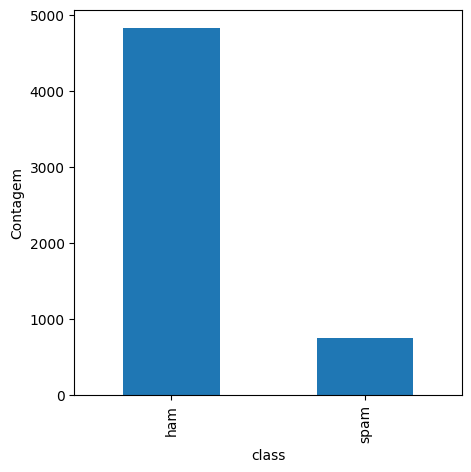

In [ ]:
sms['class'].value_counts().plot(kind = 'bar', figsize = (5, 5))
plt.ylabel('Contagem')
plt.show()

### Quais as palavras mais comuns de cada categoria?

#### Ham:


In [ ]:
# somente o texto de tais mensagens

sms[sms['class'] == 'ham']['text_clean']

,text_clean
0,go jurong point crazi avail bugi n great world...
1,ok lar joke wif u oni
3,u dun say earli hor u c alreadi say
4,nah think goe usf live around though
6,even brother like speak treat like aid patent
...,...
5565,huh lei
5568,b go esplanad fr home
5569,piti mood suggest
5570,guy bitch act like interest buy someth els nex...


In [ ]:
# considere ' ' como separador para juntar as strings desejadas

' '.join(sms[sms['class'] == 'ham']['text_clean'])

'go jurong point crazi avail bugi n great world la e buffet cine got amor wat ok lar joke wif u oni u dun say earli hor u c alreadi say nah think goe usf live around though even brother like speak treat like aid patent per request mell mell set callertun caller press copi friend callertun gonna home soon want talk stuff anymor tonight k cri enough today search right word thank breather promis wont take help grant fulfil promis wonder bless time date sunday oh k watch eh u rememb spell name yes v naughti make v wet fine way u feel way gota b serious spell name go tri month ha ha joke pay first lar da stock comin aft finish lunch go str lor ard smth lor u finish ur lunch alreadi ffffffffff alright way meet sooner forc eat slice realli hungri tho suck mark get worri know sick turn pizza lol lol alway convinc catch bus fri egg make tea eat mom left dinner feel love back amp pack car let know room ahhh work vagu rememb feel like lol wait still clear sure sarcast x want live us yeah got v ap

In [ ]:
' '.join(sms[sms['class'] == 'ham']['text_clean']).split()

['go',
 'jurong',
 'point',
 'crazi',
 'avail',
 'bugi',
 'n',
 'great',
 'world',
 'la',
 'e',
 'buffet',
 'cine',
 'got',
 'amor',
 'wat',
 'ok',
 'lar',
 'joke',
 'wif',
 'u',
 'oni',
 'u',
 'dun',
 'say',
 'earli',
 'hor',
 'u',
 'c',
 'alreadi',
 'say',
 'nah',
 'think',
 'goe',
 'usf',
 'live',
 'around',
 'though',
 'even',
 'brother',
 'like',
 'speak',
 'treat',
 'like',
 'aid',
 'patent',
 'per',
 'request',
 'mell',
 'mell',
 'set',
 'callertun',
 'caller',
 'press',
 'copi',
 'friend',
 'callertun',
 'gonna',
 'home',
 'soon',
 'want',
 'talk',
 'stuff',
 'anymor',
 'tonight',
 'k',
 'cri',
 'enough',
 'today',
 'search',
 'right',
 'word',
 'thank',
 'breather',
 'promis',
 'wont',
 'take',
 'help',
 'grant',
 'fulfil',
 'promis',
 'wonder',
 'bless',
 'time',
 'date',
 'sunday',
 'oh',
 'k',
 'watch',
 'eh',
 'u',
 'rememb',
 'spell',
 'name',
 'yes',
 'v',
 'naughti',
 'make',
 'v',
 'wet',
 'fine',
 'way',
 'u',
 'feel',
 'way',
 'gota',
 'b',
 'serious',
 'spell',
 'na

In [ ]:
Counter(' '.join(sms[sms['class'] == 'ham']['text_clean']).split()).most_common(50)

[('u', 1017),
 ('go', 417),
 ('get', 360),
 ('gt', 315),
 ('lt', 313),
 ('call', 298),
 ('come', 294),
 ('ok', 287),
 ('love', 252),
 ('know', 247),
 ('like', 245),
 ('day', 243),
 ('ur', 241),
 ('good', 234),
 ('got', 231),
 ('time', 231),
 ('want', 212),
 ('need', 178),
 ('one', 173),
 ('home', 165),
 ('lor', 162),
 ('sorri', 157),
 ('take', 154),
 ('see', 153),
 ('think', 152),
 ('da', 150),
 ('still', 150),
 ('k', 145),
 ('n', 143),
 ('today', 143),
 ('send', 141),
 ('say', 139),
 ('tell', 139),
 ('make', 135),
 ('later', 134),
 ('work', 132),
 ('dont', 132),
 ('r', 132),
 ('back', 130),
 ('hope', 129),
 ('ask', 127),
 ('pls', 123),
 ('hi', 122),
 ('meet', 120),
 ('miss', 120),
 ('happi', 119),
 ('well', 114),
 ('much', 114),
 ('night', 114),
 ('oh', 113)]

In [ ]:
count_ham = pd.DataFrame.from_dict(
    Counter(' '.join(sms[sms['class'] == 'ham']['text_clean']).split()).most_common(50))
count_ham.head()

,0,1
0,u,1017
1,go,417
2,get,360
3,gt,315
4,lt,313


In [ ]:
count_ham.columns = ['words_in_ham', 'count']
count_ham.head()

,words_in_ham,count
0,u,1017
1,go,417
2,get,360
3,gt,315
4,lt,313


#### Spam:

In [ ]:
count_spam = pd.DataFrame.from_dict(
    Counter(' '.join(sms[sms['class'] == 'spam']['text_clean']).split()).most_common(50))
count_spam.head()

,0,1
0,call,379
1,free,224
2,u,168
3,txt,154
4,text,144


In [ ]:
count_spam.columns = ['words_in_spam', 'count']
count_spam.head()

,words_in_spam,count
0,call,379
1,free,224
2,u,168
3,txt,154
4,text,144


#### Visualizando de outra forma:

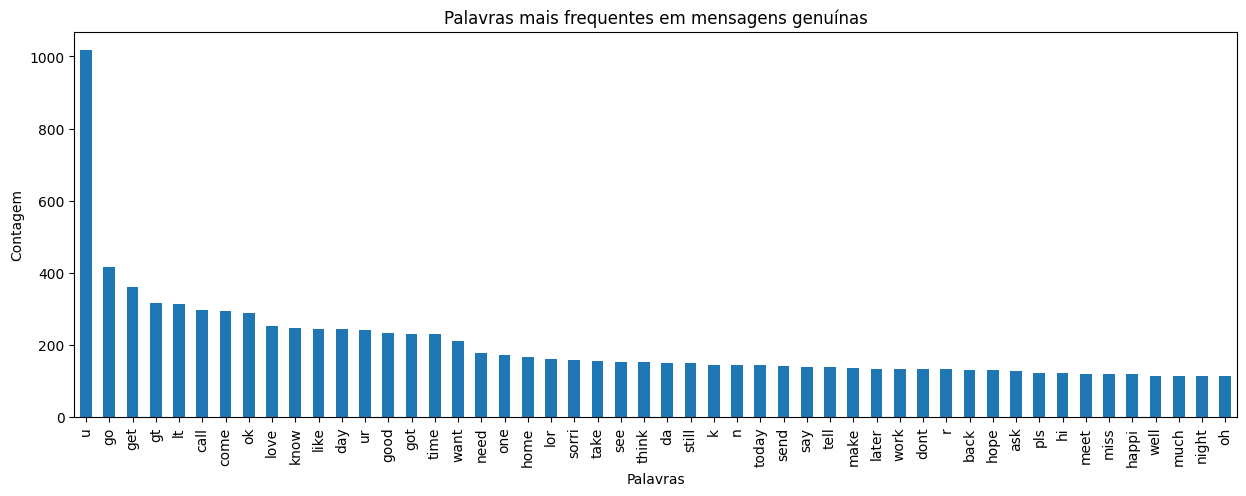

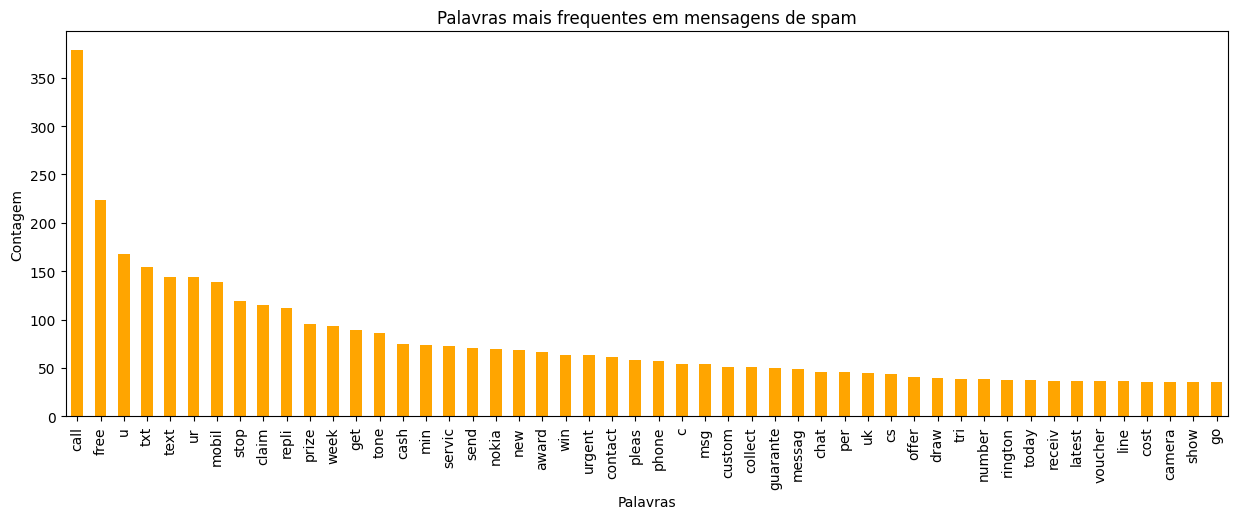

In [ ]:
count_ham.plot(kind = 'bar', legend = False, figsize = (15, 5))
plt.xticks(np.arange(50), count_ham['words_in_ham'])
plt.title('Palavras mais frequentes em mensagens genuínas')
plt.xlabel('Palavras')
plt.ylabel('Contagem')
plt.show()

count_spam.plot(kind = 'bar', legend = False, color = 'orange', figsize = (15, 5))
plt.xticks(np.arange(50), count_spam['words_in_spam'])
plt.title('Palavras mais frequentes em mensagens de spam')
plt.xlabel('Palavras')
plt.ylabel('Contagem')
plt.show()

In [ ]:
sms['text_clean']

,text_clean
0,go jurong point crazi avail bugi n great world...
1,ok lar joke wif u oni
2,free entri wkli comp win fa cup final tkts may...
3,u dun say earli hor u c alreadi say
4,nah think goe usf live around though
...,...
5567,time tri contact u u pound prize claim easi ca...
5568,b go esplanad fr home
5569,piti mood suggest
5570,guy bitch act like interest buy someth els nex...


In [ ]:
X = feature_extraction.text.CountVectorizer(binary = True).fit_transform(sms['text_clean'])
np.shape(X)

(5572, 5995)

In [ ]:
sms['class'] = sms['class'].map({'spam': 1,'ham': 0})
sms.head()

,class,text,text_clean_aux_1,text_clean_aux_2,text_clean
0,0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,go jurong point crazy available bugis n great ...,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ok lar joking wif u oni,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...,free entry wkly comp win fa cup final tkts may...,free entri wkli comp win fa cup final tkts may...
3,0,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,u dun say early hor u c already say,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...,nah think goes usf lives around though,nah think goe usf live around though


5995 atributos criados, nesse caso, palavras presentes na SMS. Armazenadas em uma matriz esparsa para economizar memória!

Atributo $j$ (coluna) na linha $i$ é 1 se a palavra associada ao índice $j$ aparece na SMS de índice $i$ e 0 caso contrário.

In [ ]:
# Conferindo os tamanhos...

print(np.shape(X))
print(np.shape(sms['class']))
print(np.shape(sms.index))

(5572, 5995)
(5572,)
(5572,)


## Classificação!

### Dividir em conjunto de treinamento e teste

In [ ]:
# Mas quero guardar os índices correspondentes para poder ler as respectivas SMS classificadas erroneamente!

X_train, X_test, y_train, y_test, idx_train, idx_test = model_selection.train_test_split(
    X, sms['class'], sms.index, test_size = 0.33, stratify = sms['class'])

print([np.shape(X_train), np.shape(X_test)])

[(3733, 5995), (1839, 5995)]


## Classificando

Vamos relembrar o classificador de Bayes ingênuo...

**Teorema** (Classificador de Bayes): A função $g: \mathbb{R}^p \to \mathcal{C}$ que minimiza o risco

$$R(g) = \mathbb{E}[\mathbb{I}(Y \neq g(\mathbf{X}))] = \mathbb{P}(Y \neq g(\mathbf{X}))$$

é o *classificador de Bayes*, dado por

$$g(\mathbf{x}) = \mathop{\mathrm{argmax}}_{d \in \mathcal{C}} \mathbb{P}(Y = d | \mathbf{X} = \mathbf{x})$$


- Estimar $\mathbb{P}(Y = d | \mathbf{X} = \mathbf{x})$ para cada classe $d \in \mathcal{C}$


- Considerar o classificador $$g(\mathbf{x}) = \mathop{\mathrm{argmax}}_{d \in \mathcal{C}} \widehat{\mathbb{P}}(Y = d | \mathbf{X} = \mathbf{x})$$

- $\mathbf{X} \in \mathbb{R}^{5995}$: vetor (aleatório) de atributos


- Matriz $X$, contendo 5572 realizações do vetor aleatório $\mathbf{X}$


- Na matriz $X$, temos que:

$$
X_{ij} =
\begin{cases}
1, & \text{se a palavra de índice $j$ aparece na SMS de índice $i$} \\
0, & \text{caso contrário}
\end{cases}
$$


- $\mathbf{X}$ é um vetor aleatório **discreto**

- Variável resposta $Y \in \{0, 1\}$


- $0 \iff$ mensagem genuína
- $1 \iff$ spam

- Como $\mathbf{X}$ é discreto, temos que:


$$\mathbb{P}(Y = 1 | \mathbf{X} = \mathbf{x}) = \frac{\mathbb{P}(\mathbf{X} = \mathbf{x} | Y = 1)\mathbb{P}(Y = 1)}{\sum_{c = 0}^{1} \mathbb{P}(\mathbf{X} = \mathbf{x} | Y = c)\mathbb{P}(Y = c)} \propto \mathbb{P}(\mathbf{X} = \mathbf{x} | Y = 1)\mathbb{P}(Y = 1)$$


$$\mathbb{P}(Y = 0 | \mathbf{X} = \mathbf{x}) = \frac{\mathbb{P}(\mathbf{X} = \mathbf{x} | Y = 0)\mathbb{P}(Y = 0)}{\sum_{c = 0}^{1} \mathbb{P}(\mathbf{X} = \mathbf{x} | Y = c)\mathbb{P}(Y = c)} \propto \mathbb{P}(\mathbf{X} = \mathbf{x} | Y = 0)\mathbb{P}(Y = 0)$$

- $\mathbb{P}(Y = d)$ estimado através da proporção amostral entre as classes


- Assumir algum modelo probabilístico em $\mathbf{X}$ para estimar $\mathbb{P}(\mathbf{X} = \mathbf{x} | Y = d)$, para $d \in \{0, 1\}$

- Hipótese ingênua: *condicionado à classe, as componentes de $\mathbf{X}$ são independentes*


- Na nossa linguagem: *sabendo qual classe de SMS estamos analisando (spam ou ham), a ocorrência ou não das palavras não se influenciam mutuamente*

- Matematicamente: *para toda classe $d \in \{0, 1\}$, fatoramos* $$\mathbb{P}(\mathbf{X} = \mathbf{x} | Y = d) = \mathbb{P}(X_1 = x_1, \dots, X_p = x_p | Y = d) = \prod_{j = 1}^{p} \mathbb{P}(X_j = x_j | Y = d)$$


- $X_j | Y = d \sim \text{Bern}(p_{dj})$

- $p_{dj}$ = denota a probabilidade da classe $d$ gerar a palavra $j$

*This event model is especially popular for classifying short texts. It has the benefit of explicitly modelling the absence of terms.*"

"*Despite the fact that the far-reaching independence assumptions are often inaccurate, the naive Bayes classifier has several properties that make it surprisingly useful in practice. In particular, the decoupling of the class conditional feature distributions means that each distribution can be independently estimated as a one-dimensional distribution. This helps alleviate problems stemming from the curse of dimensionality, such as the need for data sets that scale exponentially with the number of features.*"

Wikipedia (https://en.wikipedia.org/wiki/Naive_Bayes_classifier)

In [ ]:
NB = naive_bayes.BernoulliNB()

In [ ]:
NB.fit(X_train, y_train)

BernoulliNB()

In [ ]:
y_test_pred = NB.predict(X_test)
y_test_pred_proba = NB.predict_proba(X_test)

In [ ]:
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
# https://developers.google.com/machine-learning/crash-course/classification/accuracy

# print(1 - metrics.accuracy_score(y_test, y_test_pred))
print(NB.score(X_test, y_test))

0.9635671560630777


## Analisando as métricas

In [ ]:
# https://scikit-learn.org/stable/modules/classes.html#classification-metrics
# https://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics
# https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html#sklearn.metrics.confusion_matrix

CM_NB = metrics.confusion_matrix(y_test, y_test_pred)

In [ ]:
CM_NB

array([[1582,   10],
       [  57,  190]])

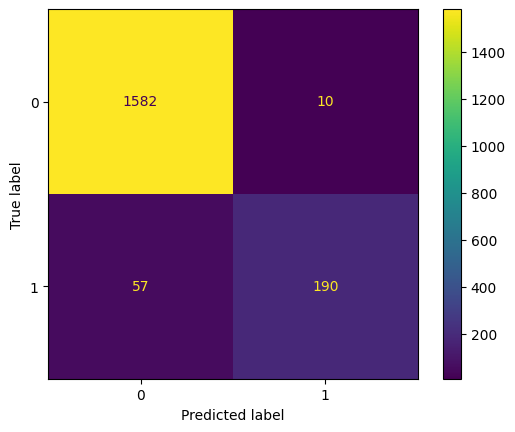

In [ ]:
metrics.ConfusionMatrixDisplay.from_estimator(NB, X_test, y_test, display_labels = NB.classes_)
plt.show()

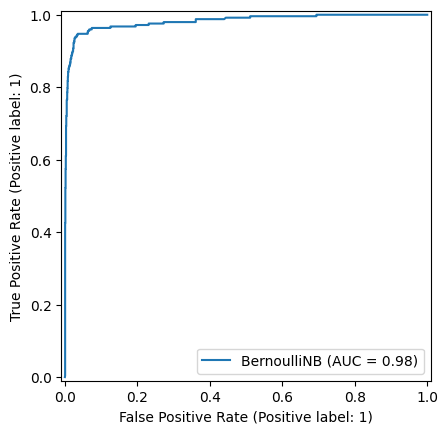

In [ ]:
metrics.RocCurveDisplay.from_estimator(NB, X_test, y_test)
plt.show()

## Analisando os erros

No caso do spam, o que é pior? Falso negativo ou falso positivo?

*   Falso negativo: Spam na caixa de entrada, deleto.
*   Falso positivo: Não-spam na caixa de spam, provavelmente jamais será lido e pode ser algo importante!

Portanto, evitar falsos negativos pode ser mais interessante!

Vendo os falsos positivos

In [ ]:
FP = np.where((y_test == 0) & (y_test_pred == 1))
FP

(array([  72,  253,  433,  469,  899, 1002, 1050, 1073, 1197, 1550]),)

In [ ]:
for idx in FP[0]:
  print('(Prob. de ser spam %f) %s' % (y_test_pred_proba[idx, 1], sms.iloc[idx_test[idx]]['text_clean']))

(Prob. de ser spam 0.999974) tell shola pleas go colleg medicin visit academ depart tell academ secretari current situat ask transfer ask someon check sagamu thing lautech vital complet medic educ nigeria less expens much less expens unless get citizen rate new zealand
(Prob. de ser spam 1.000000) ee msg na poortiyagi odalebeku hanumanji name hanuman bajarangabali maruti pavanaputra sankatmochan ramaduth mahav ee name lt gt janarig ivatt kalisidar next saturday olag ondu good news keluviri maretar ind dodda problum nalli siguviri idu matra lt gt true neglet
(Prob. de ser spam 0.955764) ey calm downon theacus itxt u cos iwana know wotu r doin thew end haventcn u age ring ur neth sat love j xxx
(Prob. de ser spam 1.000000) indian r poor india poor countri say one swiss bank director say lt gt lac crore indian money deposit swiss bank use taxless budget lt gt yrs give lt gt crore job indian villag delhi lane road forev free power supli lt gt social project everi citizen get month lt gt lt

Vendo os falsos negativos

In [ ]:
FN = np.where((y_test == 1) & (y_test_pred == 0))
FN

(array([   3,   41,   47,   96,  117,  183,  241,  264,  364,  404,  427,
         436,  456,  467,  494,  495,  566,  594,  609,  636,  655,  657,
         663,  713,  928,  939,  943,  954, 1000, 1102, 1155, 1208, 1215,
        1234, 1251, 1256, 1280, 1327, 1329, 1433, 1460, 1482, 1494, 1502,
        1503, 1508, 1539, 1568, 1620, 1636, 1650, 1714, 1723, 1729, 1740,
        1762, 1786]),)

In [ ]:
for idx in FN[0]:
  print('(Prob. de ser spam %f) %s' % (y_test_pred_proba[idx, 1], sms.iloc[idx_test[idx]]['text_clean']))

(Prob. de ser spam 0.078059) explos pick member nasdaq symbol cdgt per
(Prob. de ser spam 0.004169) remind download content alreadi paid goto mymobi tv collect content
(Prob. de ser spam 0.000000) life never much fun great came made truli special forget enjoy one gbp sms
(Prob. de ser spam 0.000002) sms ac post hello seem cool
(Prob. de ser spam 0.000010) call freephon
(Prob. de ser spam 0.022041) lookatm thank purchas video clip lookatm charg think better send video mmsto
(Prob. de ser spam 0.393494) congrat year special cinema pass call c suprman v etc free dont miss
(Prob. de ser spam 0.013901) month password wap mobsi com use wap phone pc
(Prob. de ser spam 0.003100) bloomberg messag center wait appli futur bloomberg com
(Prob. de ser spam 0.004195) pleas call immedi urgent messag wait
(Prob. de ser spam 0.353384) dear voucher holder next meal us use follow link pc enjoy dine experi
(Prob. de ser spam 0.001272) natalja invit friend repli yes see stop send stop frnd
(Prob. de ser sp

## Distâncias dois-a-dois

In [ ]:
#pdist(X, metric='euclidean')

In [ ]:
def pairwise_l2_sparse_sample(X, sample_size):
    """
    Amostra `sample_size` linhas da matriz esparsa X e calcula
    as distâncias L2 entre todas as linhas amostradas.

    Retorna apenas o vetor condensado (mesmo formato do pdist).
    """

    rng = np.random.default_rng()

    # sorteia índices diferentes
    n = X.shape[0]
    idx = rng.choice(n, size=sample_size, replace=False)

    # garante formato eficiente
    Xs = X[idx].tocsr()

    dists = []
    for i in range(sample_size):
        xi = Xs[i]
        for j in range(i+1, sample_size):
            xj = Xs[j]
            diff = xi - xj
            dist = np.sqrt(diff.multiply(diff).sum())
            dists.append(dist)

    return np.array(dists), idx

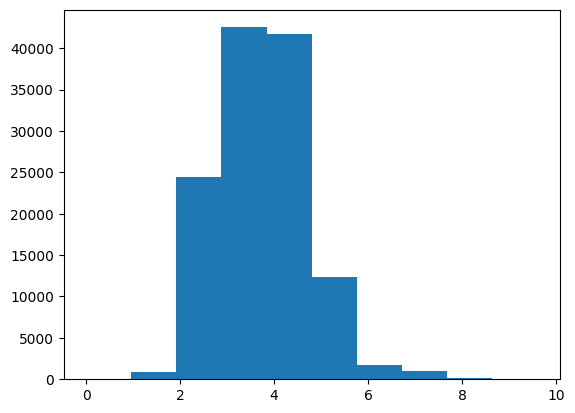

In [ ]:
d, sampled_idx = pairwise_l2_sparse_sample(X, sample_size = 500)

plt.hist(d)
plt.show()

## PCA

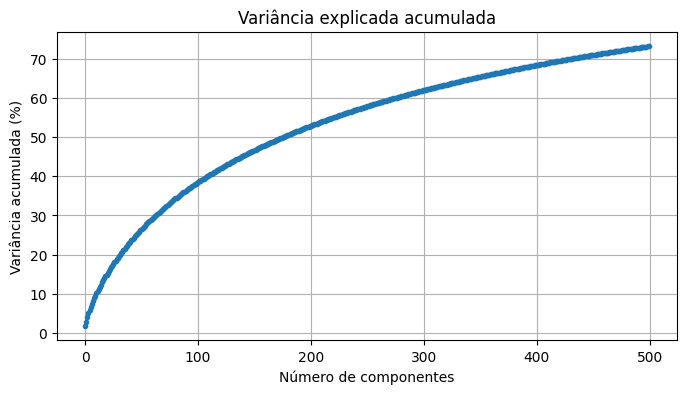

In [ ]:
pca = PCA(n_components = 500)
X_pca = pca.fit_transform(X)

explained_variance = pca.explained_variance_ratio_

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(explained_variance)*100, marker='.')
plt.xlabel("Número de componentes")
plt.ylabel("Variância acumulada (%)")
plt.title("Variância explicada acumulada")
plt.grid(True)
plt.show()

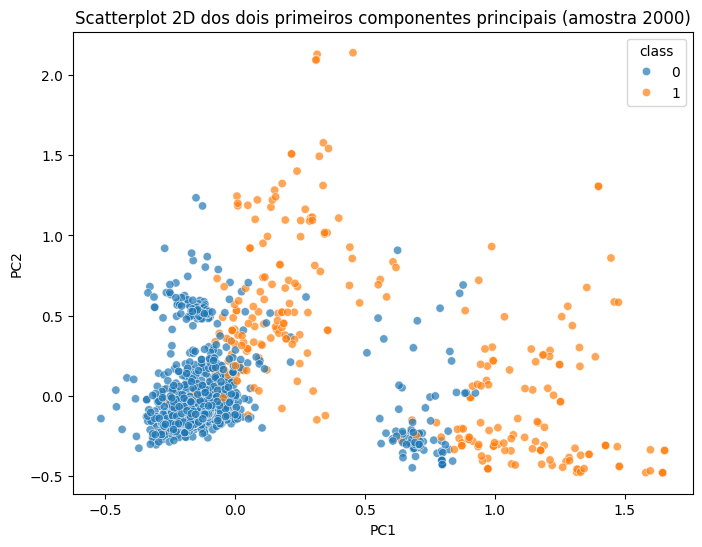

In [ ]:
df_2d = pd.DataFrame(X_pca[:, :2], columns=['PC1', 'PC2'])
df_2d['class'] = sms['class']

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_2d.sample(2000), x='PC1', y='PC2', hue='class', palette='tab10', legend='full', alpha=0.7)
plt.title("Scatterplot 2D dos dois primeiros componentes principais (amostra 2000)")
plt.show()